# Laboratorio 6 — Análisis de datos de entrada (puntos 5.1 y 5.2)

**Santiago Barrera Meza · 160005004**
Simulación Computacional · Universidad de los Llanos · Guía FO-DOC-112, laboratorio 6

Los datos `dataset-A.txt` … `dataset-D.txt` se descargaron de los enlaces de la guía y están en
la carpeta `datos/`. En Colab, subir esa carpeta (o los cuatro archivos) junto al cuaderno.

## Librerías y carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATOS = Path('datos')
FIGURAS = Path('figuras'); FIGURAS.mkdir(exist_ok=True)
RESULTADOS = Path('resultados'); RESULTADOS.mkdir(exist_ok=True)

NOMBRES = ['A', 'B', 'C', 'D']
datos = {k: np.loadtxt(DATOS / f'dataset-{k}.txt') for k in NOMBRES}
for k, x in datos.items():
    print(f'Dataset {k}: {len(x)} observaciones, primeras 5 = {np.round(x[:5], 4)}')

from statsmodels.graphics import tsaplots
from statsmodels.tsa.stattools import acf
from scipy import stats

Dataset A: 200 observaciones, primeras 5 = [0.021  0.0814 0.1562 0.1494 0.1934]
Dataset B: 200 observaciones, primeras 5 = [0.1521 0.0356 0.804  0.0073 0.0352]
Dataset C: 200 observaciones, primeras 5 = [ 1.6159  0.9267  1.1669 16.6765 19.678 ]
Dataset D: 200 observaciones, primeras 5 = [0.4637 0.2135 8.4562 8.1297 1.3658]


## 5.1 Estadística descriptiva
Varianza y desviación estándar muestrales (denominador $n-1$). Los percentiles usan la
interpolación lineal por defecto de NumPy. Se agregan asimetría y curtosis (exceso) porque
ayudan a elegir las distribuciones candidatas.

In [2]:
def descriptiva(x):
    return {
        'Tamaño de la muestra': len(x),
        'Mínimo': np.min(x),
        'Máximo': np.max(x),
        'Media': np.mean(x),
        'Varianza': np.var(x, ddof=1),
        'Desviación estándar': np.std(x, ddof=1),
        'Percentil 25% (Q1)': np.percentile(x, 25),
        'Percentil 50% (Q2 o mediana)': np.percentile(x, 50),
        'Percentil 75% (Q3)': np.percentile(x, 75),
        'Coef. de variación': np.std(x, ddof=1) / np.mean(x),
        'Asimetría': stats.skew(x, bias=False),
        'Curtosis (exceso)': stats.kurtosis(x, bias=False),
    }

tabla1 = pd.DataFrame({f'Dataset {k}': descriptiva(x) for k, x in datos.items()})
tabla1.to_csv(RESULTADOS / 'tabla1_descriptiva.csv')
pd.options.display.float_format = '{:.6g}'.format
tabla1

,Dataset A,Dataset B,Dataset C,Dataset D
Tamaño de la muestra,200,200,200,200
Mínimo,0.0209639,8.516e-05,0.926681,0.111505
Máximo,0.298966,1.55131,6669.85,17.967
Media,0.195039,0.205393,762.394,2.0605
Varianza,0.00191929,0.0524807,852170,5.41299
Desviación estándar,0.0438098,0.229087,923.13,2.32658
Percentil 25% (Q1),0.163843,0.0463288,152.912,0.634291
Percentil 50% (Q2 o mediana),0.192074,0.137676,455.558,1.40636
Percentil 75% (Q3),0.230109,0.290179,1028.59,2.52891
Coef. de variación,0.224621,1.11536,1.21083,1.12914


### Histogramas con 20 particiones

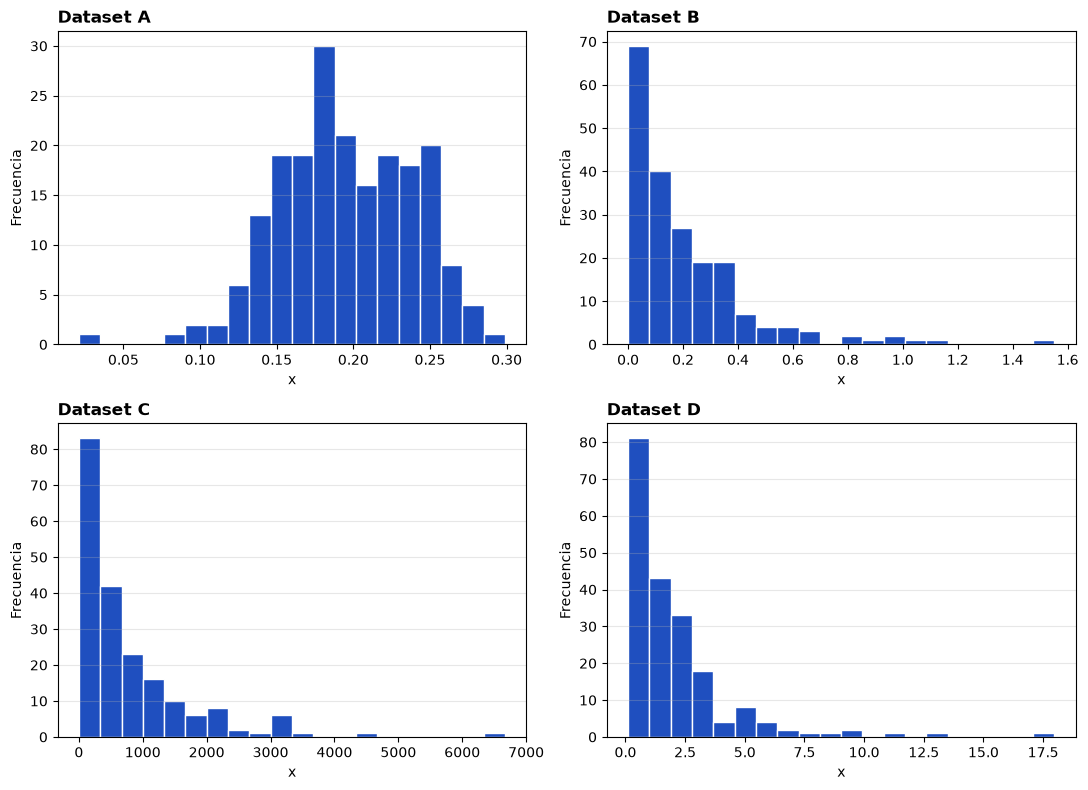

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for ax, (k, x) in zip(axs.flat, datos.items()):
    ax.hist(x, bins=20, color='#1f4fbf', edgecolor='white')
    ax.set_title(f'Dataset {k}', loc='left', fontweight='bold')
    ax.set_xlabel('x'); ax.set_ylabel('Frecuencia')
    ax.grid(axis='y', alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURAS / 'histogramas.png', dpi=160); plt.show()

## 5.2 Análisis de datos de entrada
Funciones adaptadas del cuaderno de clase *Example. Input Data Analysis.ipynb*. Cada función
dibuja sobre un eje para poner los cuatro conjuntos en una sola figura. Cambios respecto al
original:

* **Conteo de llegadas:** el original guarda el conteo del intervalo $k$ en `counts[k-1]`, lo que
  corre todas las barras una posición y deja el primer intervalo en la última. Aquí cada conteo va
  en su propio índice y los intervalos se definen como $[t_k, t_{k+1})$ para no perder llegadas
  que caen justo en un borde.
* **Media móvil:** se conserva la ventana del original (`window`, con $W$ = `window/2` a cada
  lado). Con 200 datos se usa `window = 40` ($W = 20$), porque `window = 100` del ejemplo (pensado
  para unos 1000 datos) promediaría la mitad de la muestra en cada punto.
* El horizonte $T$ de cada conjunto es la suma de sus valores (instante de la última llegada).

Los cuatro conjuntos se tratan como tiempos entre llegadas, igual que en el ejemplo de clase.

In [4]:
def plot_lag(ax, x, k):
    tsaplots.plot_acf(x, lags=20, zero=False, ax=ax, title=f'Dataset {k}')
    ax.set_xlabel('Retraso k'); ax.set_ylabel('Correlación')
    ax.set_yticks(np.arange(-1, 1.25, 0.25)); ax.set_xticks(np.arange(1, 21, 1))
    ax.set_xlim(0.5, 20.5); ax.set_ylim(-1, 1)

def plot_scatter(ax, x, k):
    ax.scatter(x[:-1], x[1:], marker='^', s=14)
    ax.grid(alpha=0.4)
    ax.set_xlim(x.min(), x.max()); ax.set_ylim(x.min(), x.max())
    ax.set_title(f'Dataset {k}'); ax.set_xlabel('Observación [k]'); ax.set_ylabel('Observación [k+1]')

def plot_patron_llegadas(ax, x, k):
    llegadas = np.cumsum(x)
    proporcion = np.arange(1, len(x) + 1) / len(x)
    ax.plot(llegadas, proporcion, 'b')
    ax.plot([0, llegadas[-1]], [0, 1], 'k--', lw=0.8, label='Tasa constante')
    ax.set_title(f'Dataset {k}'); ax.set_xlabel('Tiempo T'); ax.set_ylabel('Proporción antes de T')
    ax.legend(loc='lower right', fontsize=8)

def conteos_intervalos(x, nbins=40):
    llegadas = np.cumsum(x)
    T = llegadas[-1]
    bordes = np.linspace(0, T, nbins + 1)
    conteos, _ = np.histogram(llegadas, bins=bordes)
    return conteos, T / nbins, T

def plot_conteos(ax, x, k, nbins=40):
    conteos, ancho, T = conteos_intervalos(x, nbins)
    ax.bar(range(1, nbins + 1), conteos, width=1, edgecolor='black', color='white')
    ax.axhline(len(x) / nbins, color='red', lw=0.8, ls='--')
    ax.set_title(f'Dataset {k}: {nbins} intervalos de ancho {ancho:.4g} entre 0 y {T:.4g}', fontsize=9)
    ax.set_xlabel('Intervalo'); ax.set_ylabel('Conteo')

def media_movil(x, window=40):
    mid = round(window / 2)
    n = len(x)
    return np.array([np.mean(x[max(0, i - mid): min(n, i + mid + 1)]) for i in range(n)])

def plot_media_movil(ax, x, k, window=40):
    y = media_movil(x, window)
    m, s = np.mean(y), np.std(y)
    ax.plot(y)
    ax.axhline(m, color='black'); ax.axhline(m + 3 * s, color='green'); ax.axhline(m - 3 * s, color='green')
    ax.set_ylim(m - 9 * s, m + 9 * s); ax.set_xlim(0, len(y))
    ax.set_title(f'Dataset {k}: media móvil, ventana {window}')
    ax.set_xlabel('Posición'); ax.set_ylabel('Media móvil')

def plot_secuencia(ax, x, k):
    ax.plot(x, 'r.', ms=4)
    ax.set_title(f'Dataset {k}'); ax.set_xlabel('Orden de la observación'); ax.set_ylabel('Valor $x_i$')

def figura(fn, archivo, titulo):
    fig, axs = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (k, x) in zip(axs.flat, datos.items()):
        fn(ax, x, k)
    fig.suptitle(titulo, fontweight='bold')
    fig.tight_layout(); fig.savefig(FIGURAS / archivo, dpi=160); plt.show()

### Secuencia de valores en orden de ocurrencia

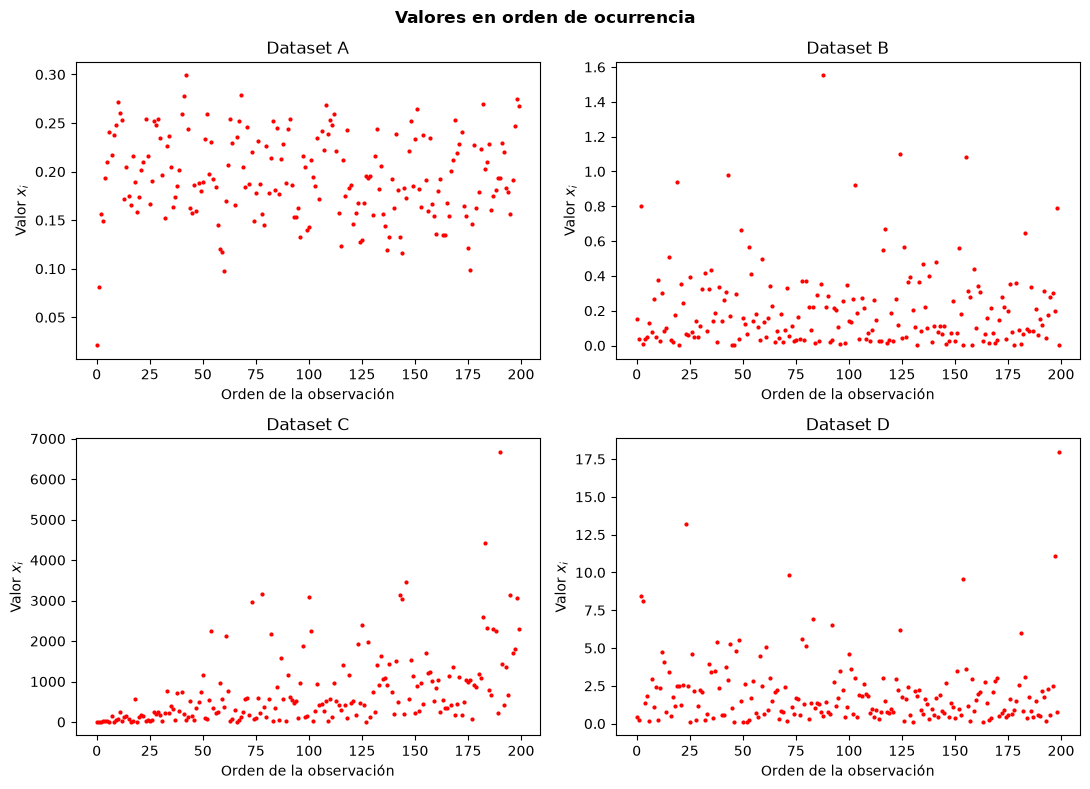

In [5]:
figura(plot_secuencia, 'secuencia.png', 'Valores en orden de ocurrencia')

### a. Correlaciones de retraso estimadas (*Estimated lag correlations*)

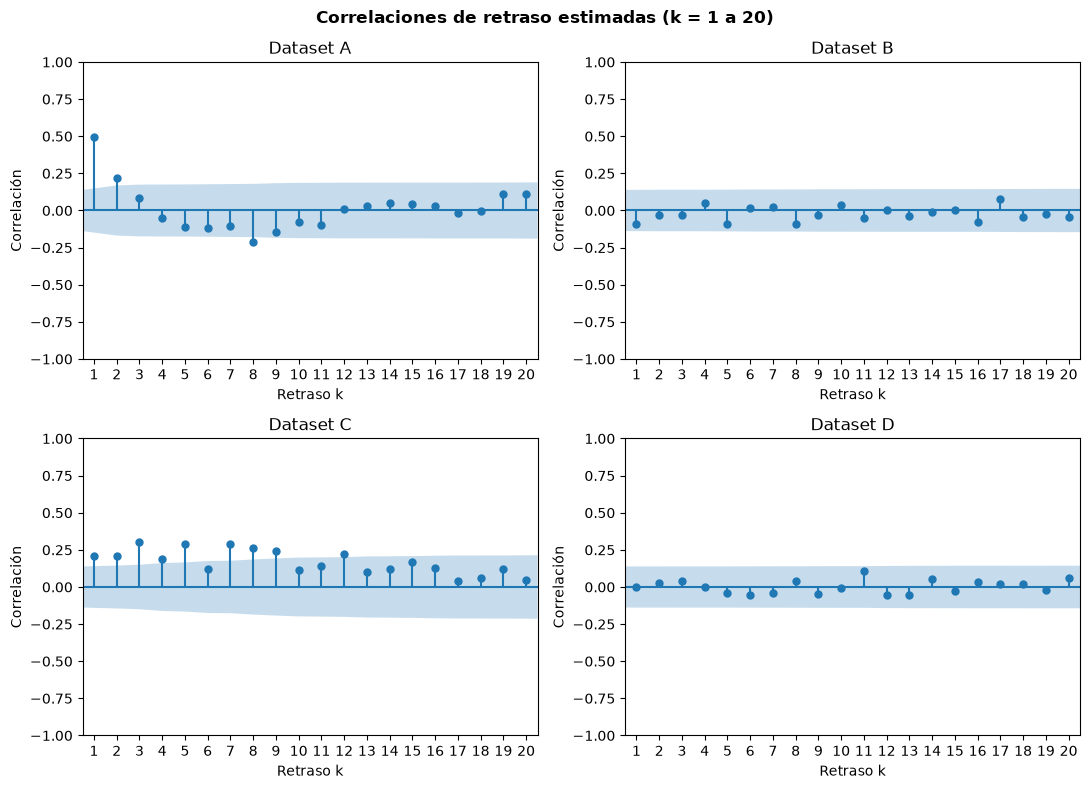

In [6]:
figura(plot_lag, 'correlaciones.png', 'Correlaciones de retraso estimadas (k = 1 a 20)')

### b. Diagrama de dispersión (*Scatter diagram*)

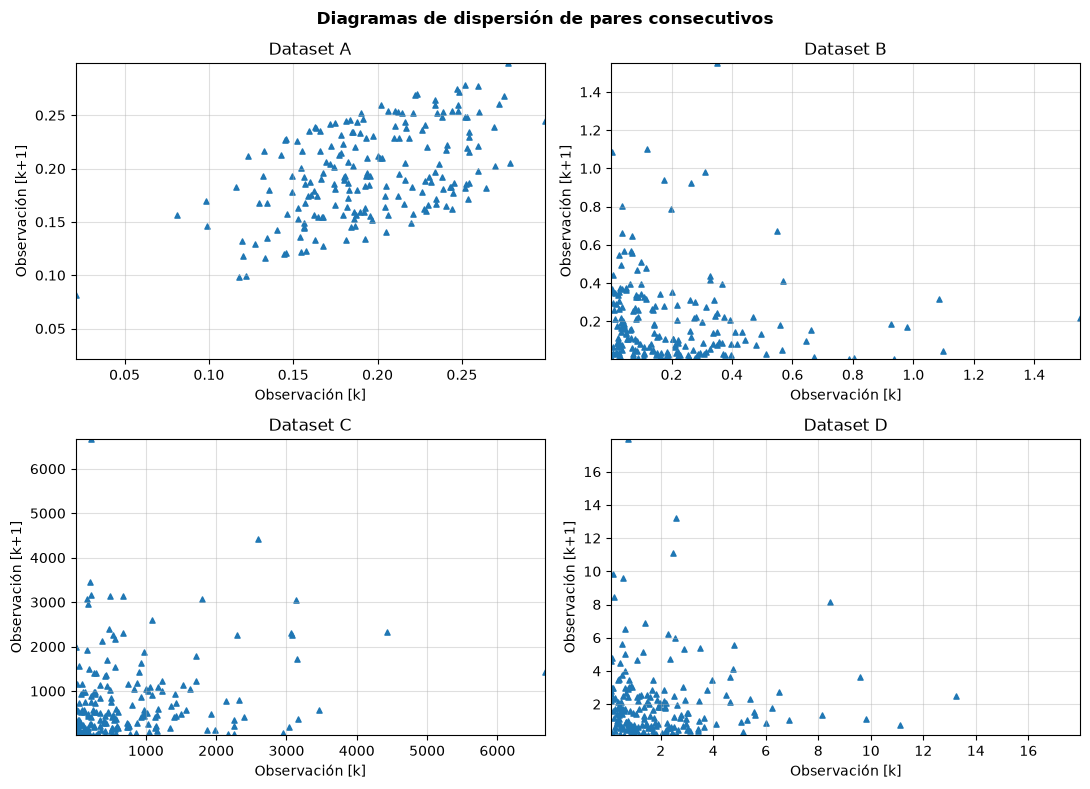

In [7]:
figura(plot_scatter, 'dispersion.png', 'Diagramas de dispersión de pares consecutivos')

### c. Patrón de hora de llegada (*Arrival time pattern*)

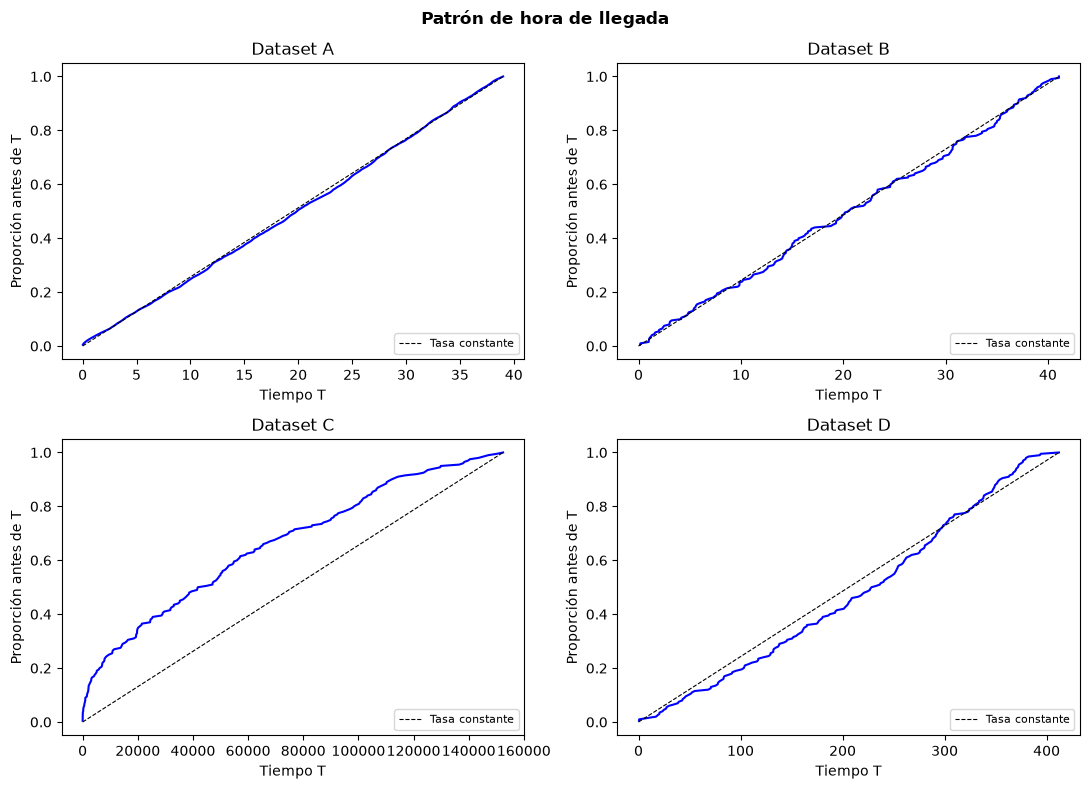

In [8]:
figura(plot_patron_llegadas, 'patron_llegadas.png', 'Patrón de hora de llegada')

### d. Conteo de llegadas vs intervalos (*Arrival counts vs intervals*)

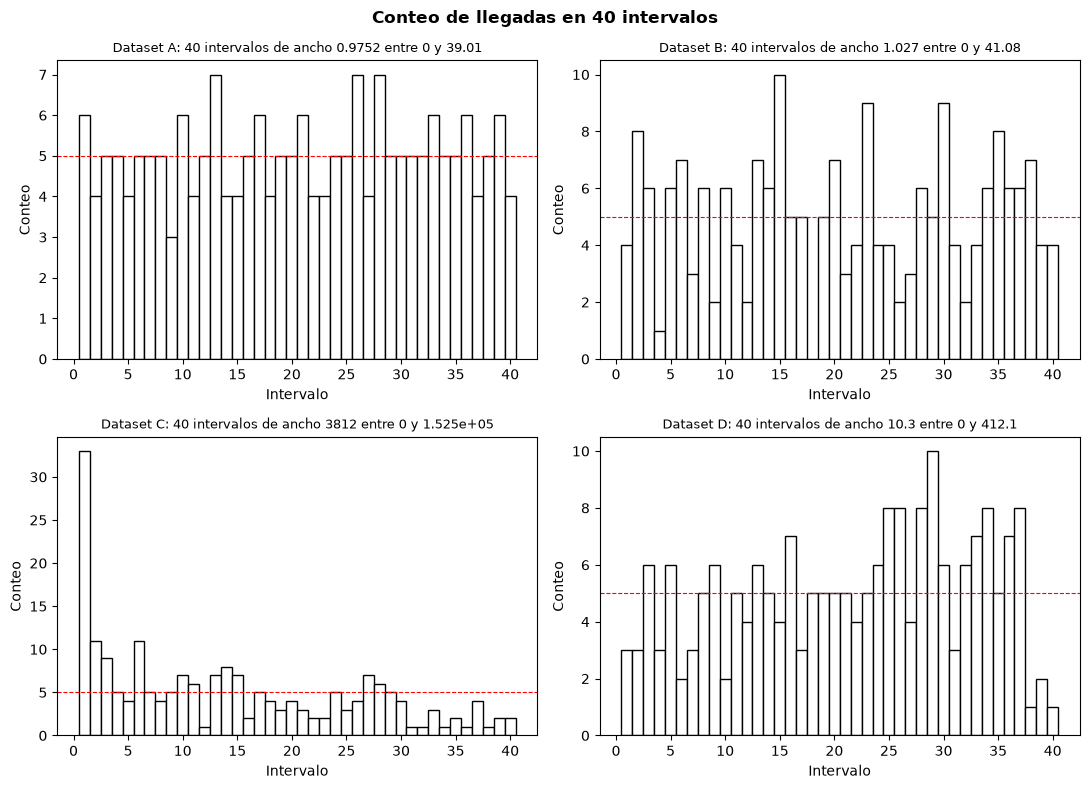

In [9]:
figura(plot_conteos, 'conteos.png', 'Conteo de llegadas en 40 intervalos')

### e. Gráfico de media móvil (*Moving average plot*)

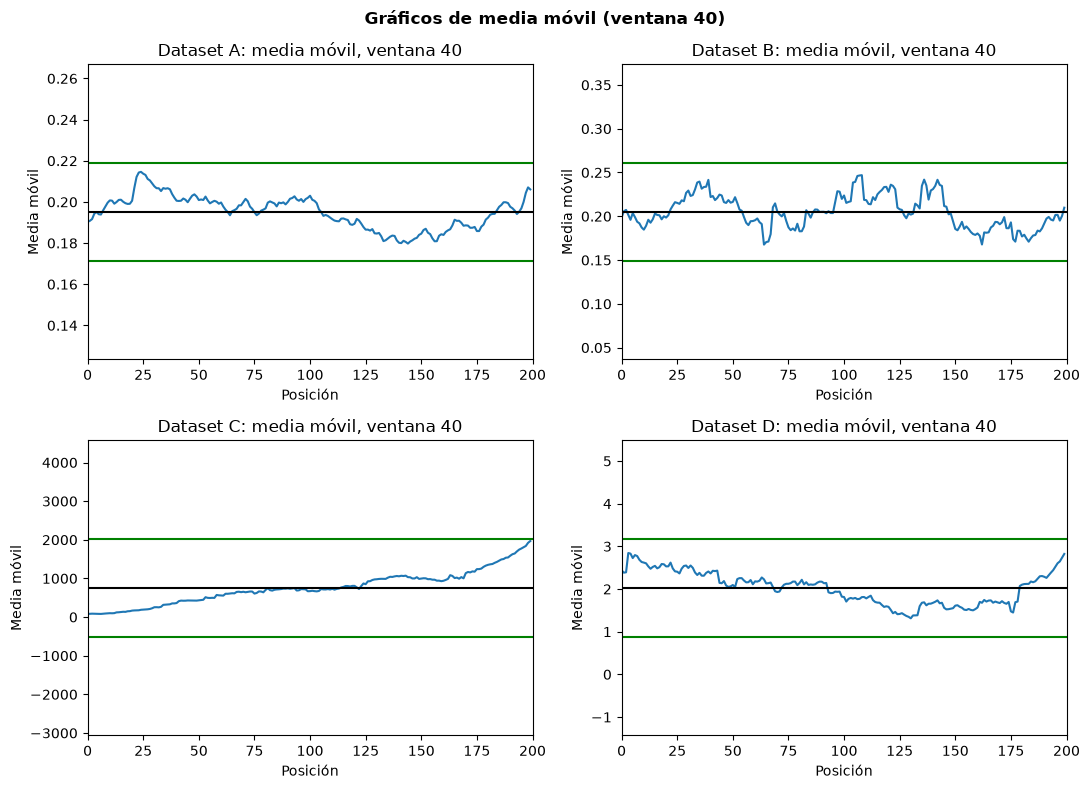

In [10]:
figura(plot_media_movil, 'media_movil.png', 'Gráficos de media móvil (ventana 40)')

### Resumen numérico de independencia y estabilidad
Las gráficas son el criterio principal, como recomienda el material de clase. Esta tabla solo
cuantifica lo que muestran: las correlaciones de retraso 1 a 3 frente a la banda aproximada
$\pm 2/\sqrt{n}$, cuántos de los retrasos 1 a 10 salen de esa banda, y la media de cada mitad y
cada cuarto de la muestra. El cociente de medias compara la segunda mitad con la primera.

In [11]:
n = 200
banda = 2 / np.sqrt(n)
filas = {}
for k, x in datos.items():
    r = acf(x, nlags=10)[1:]
    cuartos = [q.mean() for q in np.array_split(x, 4)]
    filas[f'Dataset {k}'] = {
        'r1': r[0], 'r2': r[1], 'r3': r[2],
        'Retrasos 1-10 fuera de banda': int(np.sum(np.abs(r) > banda)),
        'Media 1.a mitad': x[:100].mean(), 'Media 2.a mitad': x[100:].mean(),
        'Cociente de medias': x[100:].mean() / x[:100].mean(),
        'Media por cuartos': ' / '.join(f'{c:.4g}' for c in cuartos),
    }
tabla_iid = pd.DataFrame(filas)
tabla_iid.to_csv(RESULTADOS / 'tabla_independencia.csv')
print(f'Banda aproximada ±2/sqrt(n) = ±{banda:.3f}')
tabla_iid

Banda aproximada ±2/sqrt(n) = ±0.141


,Dataset A,Dataset B,Dataset C,Dataset D
r1,0.492202,-0.0923395,0.208361,-0.00238143
r2,0.220557,-0.0315445,0.207718,0.0298101
r3,0.085472,-0.0282011,0.300761,0.0435264
Retrasos 1-10 fuera de banda,4,0,8,0
Media 1.a mitad,0.19876,0.204951,417.558,2.28299
Media 2.a mitad,0.191317,0.205836,1107.23,1.83801
Cociente de medias,0.962553,1.00432,2.65168,0.805088
Media por cuartos,0.2015 / 0.196 / 0.189 / 0.1937,0.2172 / 0.1927 / 0.2109 / 0.2008,191 / 644.1 / 963.6 / 1251,2.585 / 1.981 / 1.52 / 2.156
